# TP Outils Mathématiques - Analyse de Fourier sur des sons

# NOMS du binôme : Julcinia OKE, Fidèle, IHOGOZA Kedia

La **transformée de Fourier** est un formidable outil d’analyse des signaux musicaux. On la rencontre notamment pour ce qui concerne le filtrage, le traitement, la synthèse de sons, etc. 
Une manifestation simple du spectre de Fourier peut être facilement obtenue avec une chaîne Hi-Fi, ou avec un logiciel de lecture de sons. En effet, les barres qui évoluent en fonction du temps quand on lit un morceau de musique n’est rien d’autre que le spectre de Fourier du son qui est en train d’être joué !


L’analyse spectrale d’un signal consiste à trouver toutes les sinusoïdes qui contribuent significativement au signal : cela veut dire identifier les **fréquences** et les **amplitudes** des sinusoïdes associées. Un **spectre de Fourier, ou spectre fréquentiel**, est une représentation graphique permettant de visualiser ces deux grandeurs, où les fréquences sont en abscisses et les amplitudes en ordonnées.


Après, *en musique*, certains termes spécifiques sont utilisés afin d’évoquer les notions que nous venons de voir. Notamment :

• La **hauteur d’un son** désigne la **fréquence fondamentale** d’un son musical. Notons que la plupart des instruments de musique émettent des sons complexes. En musique, il y a une correspondance entre le nom d’une note (do, ré, mi, …) et sa hauteur (fréquence). Par exemple, le son du diapason est le *la* international de fréquence 440 Hz.

. un **harmonique**  est en acoustique une des composantes d’un son complexe. Dans la nature, lorsqu’un un corps sonore (telles qu’une corde ou une membrane) vibre, une fréquence fondamentale est émise. Des harmoniques sont également émis par résonance de cette fondamentale. Notez que la fréquence d’un partiel harmonique est nécessairement un multiple entier de la fondamentale.

• Le **timbre** prend en compte l’importance des harmoniques du son musical. En effet, si deux instruments différents jouent la même note (même fréquence fondamentale), le timbre varie d’un instrument à l’autre. 


En particulier, l'analyse de Fourier permet d’obtenir une représentation Temps-Fréquence d’un enregistrement musical, appelée **spectrogramme**. En pratique, le spectrogramme est généré avec la TFCT (Transformée de Fourier à court terme) calculée sur des segments successifs de signal. Le spectrogramme permet ainsi de visualiser la variation au cours du temps des principales composantes fréquentielles de l’enregistrement musical. 





In [1]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
import IPython

### Chargement de fichier audio

Chargement du fichier audio : Le fichier audio est chargé avec librosa.load(), qui retourne le signal audio et la fréquence d'échantillonnage (sr).

In [2]:
# Charger le fichier audio
# Remplacez 'Do.mp3 ' par le chemin de votre fichier audio
filename = 'C:/Users/Etudiant/OneDrive/Documents/fidel/Projet/programmation_Python/SourcesTP_OutilMath/Enregistrements/Film2.mp3'
signal, sr = librosa.load(filename)

In [3]:
# Jouer le son 
import IPython
IPython.display.Audio(filename)

# A. Etude fréquentielle pure par transformée de Fourier rapide (FFT)

### 1) Calcul de la FFT :
La FFT est calculée pour transformer le signal en domaine fréquentiel, et les fréquences et magnitudes sont extraites.

In [7]:
# Calcul de la transformée de Fourier (FFT)
fft = np.fft.fft(signal)
magnitude = np.abs(fft)  # Magnitude de la FFT
frequencies = np.fft.fftfreq(len(magnitude), 1/sr)  # Fréquences correspondantes


### 2) Affichage du spectre de fréquences : 
Un graphique montre les fréquences présentes dans le signal, ce qui aide à visualiser les pics correspondant aux notes jouées.

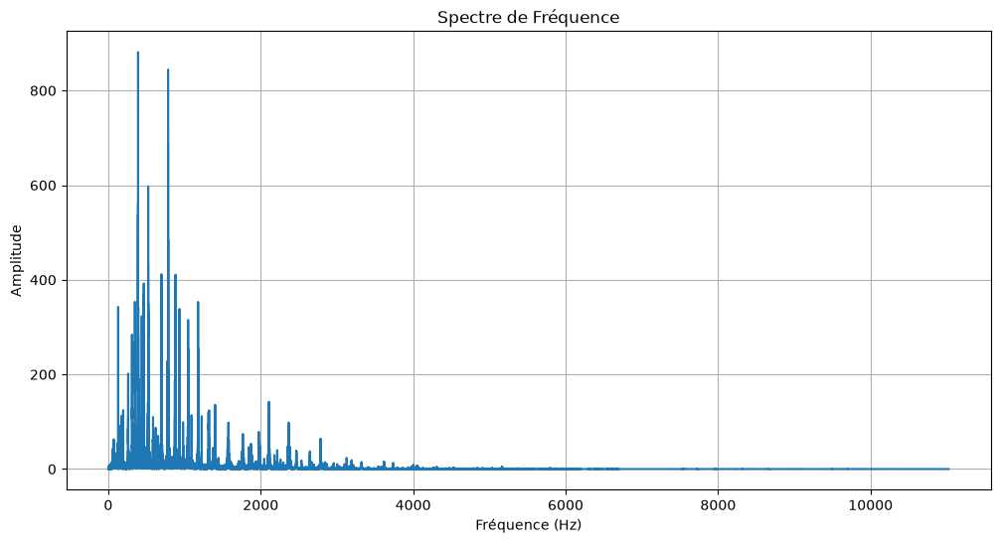

In [8]:
# Filtrer les fréquences négatives
positive_frequencies = frequencies[:len(frequencies)//2]
positive_magnitude = magnitude[:len(magnitude)//2]


# Affichage du spectre de fréquence
plt.figure(figsize=(12, 6))
plt.plot(positive_frequencies, positive_magnitude)
plt.title("Spectre de Fréquence")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

### 3)  Identifier les fréquences dominantes : 
Analyser les résultats de la FFT pour trouver les pics de fréquences correspondant aux notes jouées.

In [133]:
# Détection des fréquences dominantes
valseuil=0.05
threshold = max(positive_magnitude) * valseuil  # Seuil pour détecter les pics significatifs
idx=np.where(positive_magnitude > threshold)
peaks = positive_frequencies[positive_magnitude > threshold]

print('Fréquence en Hz :',peaks,'Amplitude :',positive_magnitude[idx])

Fréquence en Hz : [ 180.  190.  200.  210.  380.  390.  400.  410.  570.  580.  590.  600.
  610.  740.  750.  760.  770.  780.  790.  800.  810.  820.  830.  840.
  960.  970.  980.  990. 1000. 1180. 1360. 1370. 1380. 1390. 1400. 1770.
 1780. 1970. 1980. 2180.] Amplitude : [0.16412006 0.6279627  0.39382368 0.16262813 0.13465104 0.76347524
 0.2404205  0.12978603 0.1604978  0.3337725  0.99205446 0.20101945
 0.12459011 0.14177245 0.18351844 0.24236295 0.41274565 1.410908
 0.9490951  0.36286065 0.23598439 0.17675431 0.14847478 0.12579656
 0.12396936 0.2505256  2.367519   0.28092092 0.14641093 0.43047917
 0.13127688 0.3407288  0.8694495  0.2101569  0.12973359 0.14171836
 0.25274894 0.13547742 0.55701935 0.41366315]


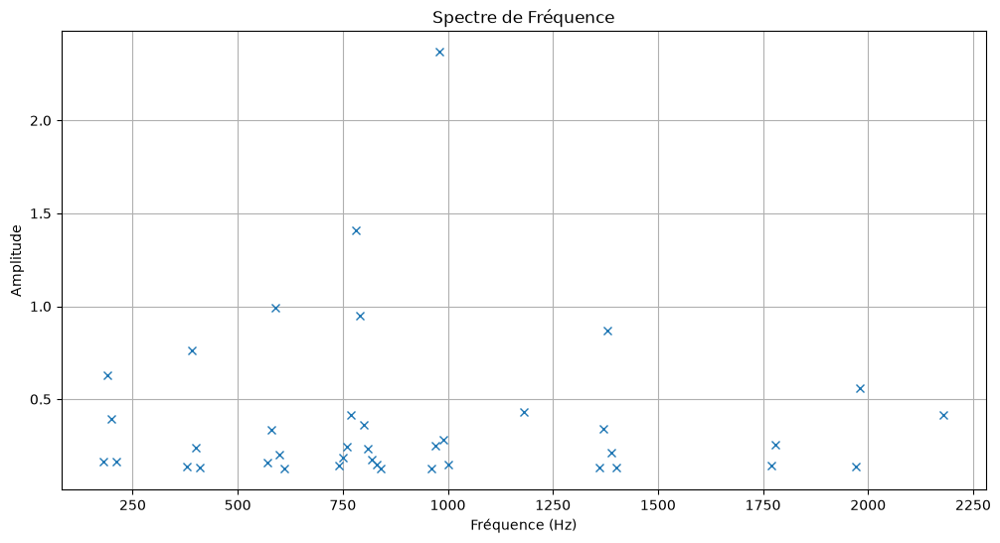

In [134]:
# Affichage du spectre de fréquence après filtrage
plt.figure(figsize=(12, 6))
plt.plot(peaks, positive_magnitude[idx],'x')
plt.title("Spectre de Fréquence")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

### 4) Associer les fréquences aux notes musicales : 
On va utiliser une table de correspondance pour associer les fréquences détectées aux notes musicales.

La formule de base pour calculer les fréquences des notes musicales d’une gamme à tempérament égal :
$$f_n=f_0*2^{n/12}$$

où
- $f_n$ est la fréquence de la note, correspondante aux demi-tons n loin de la hauteur de référence la 440 ;
- $f_0$ est la fréquence d’une note fixe utilisée comme référence pour l’accordage. Il s’agit généralement d’une hauteur de référence de 440 Hz appelée la 440 ou la note le la (la4 ou A4)
- $n$ correspond au numéro des demi-tons de la hauteur de référence ; n > 0 pour les notes supérieures à la hauteur de référence et n < 0 pour les notes inférieures à la hauteur de référence.

Pour calculer les fréquences des notes musicales à partir d’un numéro de note MIDI connu $n_m$ et une hauteur de référence la 440, et vice versa, on peut utiliser ces formules 
$$n_m=12*log_2(\frac{f_n}{440})+69$$
où 69 correspond au numéro de note MIDI de A4 (la4).

In [135]:
# Fonction pour associer une fréquence à une note
def frequency_to_note(freq):
    # Notes de référence (La 4 = 440 Hz)
    A4 = 440
    # Calcul de l'indice de note
    note_number = 12 * np.log2(freq / A4) + 69
    # Table de correspondance des notes
    note_names = ['Do', 'Do#', 'Ré', 'Ré#', 'Mi', 'Fa', 'Fa#', 'Sol', 'Sol#', 'La', 'La#', 'Si']
    note_index = int(round(note_number)) % 12
    octave = int(round(note_number)) // 12 - 1
    return note_names[note_index] + str(octave)


In [136]:
# Affichage des notes détectées
detected_notes = [frequency_to_note(freq) for freq in peaks if freq > 20]  # On ignore les très basses fréquences
print("Notes détectées :", np.unique(detected_notes))

Notes détectées : ['Do#5' 'Do#7' 'Fa#3' 'Fa#4' 'Fa#5' 'Fa6' 'La6' 'Ré#5' 'Ré5' 'Ré6' 'Si5'
 'Si6' 'Sol#3' 'Sol#4' 'Sol#5' 'Sol3' 'Sol4' 'Sol5']


##  5) Reconstitution de la note de musique par Transformée de Fourier inverse



In [137]:
# Création d'un spectre simplifié pour la synthèse en iFFT    
simplified_fft = np.zeros_like(fft, dtype=complex)
for freq in peaks:
    idx = np.argmin(np.abs(frequencies - freq))
    simplified_fft[idx] = fft[idx]  # On conserve la magnitude de la fréquence dominante

    
# Reconstituer le signal temporel avec l'iFFT
reconstructed_signal = np.fft.ifft(simplified_fft).real


In [138]:
import soundfile as sf

# Sauvegarder le signal synthétisé en fichier audio
sf.write('synthesized_note_audio.wav',reconstructed_signal, sr)

#print("Le signal synthétisé a été enregistré sous le nom 'synthesized_note_audio.wav'")
IPython.display.Audio('synthesized_note_audio.wav')

# B. Analyse fréquentielle du signal audio avec une fenêtre glissante

Grâce à la première partie, nous pouvons détecter les notes qui ont été jouées. Cependant, l'inconvénient de l'analyse purement fréquentielle est qu'on ne peut pas savoir à quel moment ces notes ont été jouées. Dans la suite, nous allons donc considérer une fenêtre glissante temporelle. 

Pour analyser un fichier audio et reconnaître les notes jouées sur une fenêtre glissante temporelle, nous allons diviser le signal audio en segments ou "fenêtres" de durée fixe, appliquer la transformée de Fourier sur chaque fenêtre, puis identifier les fréquences dominantes dans chaque segment pour déterminer les notes jouées.

### Fenêtrage temporel : 
Diviser le signal en segments avec une durée déterminée (par exemple, 0.1 ou 0.2 secondes) en utilisant une fenêtre glissante.

In [139]:
# Paramètres de la fenêtre glissante
window_duration = 0.1  # Durée de la fenêtre en secondes
hop_duration = 0.02 # Pas de glissement en secondes

#Appliction de ces paramètres au signal
window_size = int(window_duration * sr)  # Taille de la fenêtre en échantillons
hop_size = int(hop_duration * sr)  # Taille du pas en échantillons

In [140]:
# Initialisation pour stocker les notes détectées
detected_notes = []

# Itération sur le signal avec une fenêtre glissante
for start in range(0, len(signal) - window_size, hop_size):
    window_signal = signal[start:start + window_size]
    
    # Calcul de la FFT de la fenêtre
    fft = np.fft.fft(window_signal)
    magnitude = np.abs(fft)  # Magnitude de la FFT
    frequencies = np.fft.fftfreq(len(magnitude), 1/sr)  # Fréquences correspondantes
    
    # Filtrage des fréquences négatives
    positive_frequencies = frequencies[:len(frequencies)//2]
    positive_magnitude = magnitude[:len(magnitude)//2]

    # Détection des fréquences dominantes
    threshold = max(positive_magnitude) * valseuil  # Seuil pour détecter les pics significatifs
    peaks = positive_frequencies[positive_magnitude > threshold]

    # Conversion des fréquences en notes et ajout à la liste
    notes = [frequency_to_note(freq) for freq in peaks if freq > 20]  # On ignore les très basses fréquences
    detected_notes.append(list(np.unique(notes)))


In [141]:
# Affichage des notes détectées
for i, notes in enumerate(detected_notes):
    print(f"Fenêtre {i+1} : Notes détectées -> {(notes)}")

Fenêtre 1 : Notes détectées -> [np.str_('Do#2'), np.str_('Do#4'), np.str_('Do#5'), np.str_('Do#6'), np.str_('Do4'), np.str_('Do5'), np.str_('Do6'), np.str_('Fa#2'), np.str_('Fa#3'), np.str_('Fa#4'), np.str_('Fa3'), np.str_('Fa4'), np.str_('Fa6'), np.str_('La#3'), np.str_('La#4'), np.str_('La#6'), np.str_('La4'), np.str_('La6'), np.str_('Mi4'), np.str_('Mi6'), np.str_('Ré#1'), np.str_('Ré#4'), np.str_('Ré#6'), np.str_('Ré3'), np.str_('Ré4'), np.str_('Ré5'), np.str_('Ré6'), np.str_('Ré7'), np.str_('Si1'), np.str_('Si3'), np.str_('Si4'), np.str_('Si5'), np.str_('Sol#3'), np.str_('Sol#4'), np.str_('Sol4'), np.str_('Sol5'), np.str_('Sol6'), np.str_('Sol7')]
Fenêtre 2 : Notes détectées -> [np.str_('Do#4'), np.str_('Do#5'), np.str_('Do#6'), np.str_('Do4'), np.str_('Do5'), np.str_('Do6'), np.str_('Fa#4'), np.str_('Fa4'), np.str_('La#3'), np.str_('La#4'), np.str_('La#6'), np.str_('La4'), np.str_('La6'), np.str_('Mi4'), np.str_('Mi6'), np.str_('Ré#4'), np.str_('Ré#6'), np.str_('Ré4'), np.str_('R

# C. Reconstitution des notes par transformée de Fourier inverse

**Reconstruction du Signal :** Avec l’inverse de Fourier (iFFT), on reconstruit le signal temporel basé sur les fréquences dominantes de chaque fenêtre. On ajoute chaque segment reconstruit dans le tableau synthesized_signal en respectant la position dans le signal global.

In [142]:
# Création d'un tableau vide pour stocker le signal synthétisé
synthesized_signal = np.zeros(len(signal))

# Itération sur le signal avec une fenêtre glissante
for start in range(0, len(signal) - window_size, hop_size):
    window_signal = signal[start:start + window_size]
    
    # Calcul de la FFT de la fenêtre
    fft = np.fft.fft(window_signal)
    magnitude = np.abs(fft)  # Magnitude de la FFT
    frequencies = np.fft.fftfreq(len(magnitude), 1/sr)  # Fréquences correspondantes
    
    # Filtrage des fréquences négatives
    positive_frequencies = frequencies[:len(frequencies)//2]
    positive_magnitude = magnitude[:len(magnitude)//2]

    # Détection des fréquences dominantes
    threshold = max(positive_magnitude) * valseuil
    dominant_freqs = positive_frequencies[positive_magnitude > threshold]
    
    # Création d'un spectre simplifié pour la synthèse
    simplified_fft = np.zeros_like(fft, dtype=complex)
    for freq in dominant_freqs:
        idx = np.argmin(np.abs(frequencies - freq))
        # Conserver la magnitude de la fréquence dominante
        simplified_fft[idx] = fft[idx]

    # Recréer le signal temporel avec l'iFFT
    synthesized_window = np.fft.ifft(simplified_fft).real

    # Additionner le signal synthétisé à la position de la fenêtre
    synthesized_signal[start:start + window_size] += synthesized_window[:window_size]


In [143]:
import soundfile as sf

# Sauvegarder le signal synthétisé en fichier audio
sf.write('synthesized_audio.wav', synthesized_signal, sr)

print("Le signal synthétisé a été enregistré sous le nom 'synthesized_audio.wav'")
IPython.display.Audio('synthesized_audio.wav')

Le signal synthétisé a été enregistré sous le nom 'synthesized_audio.wav'


# Votre étude : points à considérer pour les sons + complexes


A partir du dossier **Enregistrements**, 12 enregistrements (et 5 versions longues) issus de BO de films vous sont proposés. Ces sons étant plus complexes, il vous est par conséquent demandé de réaliser une petite étude sur les paramètres adéquats suivants pour avoir une reconstitution correcte : 

-  **Précision et Bruit :** Le seuil pour détecter les fréquences dominantes (*threshold et valseuil*) peut être ajusté pour améliorer la détection et éviter le bruit.

- **Paramètres de Fenêtre et de Pas :** Ajustez *window_duration* et *hop_duration* pour capturer suffisamment d'information sans perdre les détails des notes jouées rapidement.

Ce travail est à réaliser par **binôme** et il vous sera demandé de rendre le notebook comprenant le code **bien commenté** de votre étude sur au moins 2 enregistrements. 
Des commentaires sur votre étude doit figurer sur la capsule **Vos commentaires sur votre étude**. 

In [127]:
# Votre étude à coder et commenter

In [23]:
"""
Etude de l'enregistrement Film2.mp3
"""

import numpy as np
import librosa
import soundfile as sf
import IPython

def frequency_to_note(freq):
    # Notes de référence (La 4 = 440 Hz)
    A4 = 440
    # Calcul de l'indice de note
    note_number = 12 * np.log2(freq / A4) + 69
    # Table de correspondance des notes
    note_names = ['Do', 'Do#', 'Ré', 'Ré#', 'Mi', 'Fa', 'Fa#', 'Sol', 'Sol#', 'La', 'La#', 'Si']
    note_index = int(round(note_number)) % 12
    octave = int(round(note_number)) // 12 - 1
    return note_names[note_index] + str(octave)

# B & C
def window_frequency_analysis(signal, sr, window_duration, hop_duration, valseuil):
    detected_notes = []
    hop_size = int(hop_duration * sr)
    window_size = int(window_duration * sr)
    synthesized_signal = np.zeros(len(signal))
    
    for start in range(0, len(signal) - window_size, hop_size):
        window_signal = signal[start:start + window_size]
        fft = np.fft.fft(window_signal)
        magnitude = np.abs(fft)
        frequencies = np.fft.fftfreq(len(magnitude), 1/sr)
        
        # Filtrage des fréquences négatives
        positive_frequencies = frequencies[:len(frequencies)//2]
        positive_magnitude = magnitude[:len(magnitude)//2]
    
        # Détection des fréquences dominantes
        threshold = max(positive_magnitude) * valseuil
        peaks = positive_frequencies[positive_magnitude > threshold]
    
        # Conversion des fréquences en notes et ajout à la liste
        notes = [frequency_to_note(freq) for freq in peaks if freq > 20]
        detected_notes.append(list(np.unique(notes)))

        dominant_freqs = positive_frequencies[positive_magnitude > threshold]
        simplified_fft = np.zeros_like(fft, dtype=complex)
        for freq in dominant_freqs:
            idx = np.argmin(np.abs(frequencies - freq))
            simplified_fft[idx] = fft[idx]
        synthesized_window = np.fft.ifft(simplified_fft).real
        synthesized_signal[start:start + window_size] += synthesized_window[:window_size]
    return synthesized_signal

def save_synthesized_signal(synthesized_signal, sr):
    sf.write('synthesized_audio.wav', synthesized_signal, sr)
    print("Le signal synthétisé a été enregistré sous le nom 'synthesized_audio.wav'")
    IPython.display.display(IPython.display.Audio('synthesized_audio.wav'))

def main(filename,window_duration,hop_duration,valseuil):
    signal, sr = librosa.load(filename)
    
    
    # Affichage du signal original
    plt.plot(signal)
    plt.title("Représentation Temporelle du Signal de départ")
    plt.xlabel("Temps (échantillons)")
    plt.ylabel("Amplitude")
    plt.grid()
    plt.show()
    
    # Application de l'analyse fréquentielle par fenêtre glissante
    synthesized_signal = window_frequency_analysis(signal, sr, window_duration, hop_duration, valseuil)
    save_synthesized_signal(synthesized_signal, sr)
    
    # Affichage du signal synthétisé
    plt.plot(synthesized_signal)
    plt.title("Représentation Temporelle du Signal Audio reconstitué")
    plt.xlabel("Temps (échantillons)")
    plt.ylabel("Amplitude")
    plt.grid()
    plt.show()




In [ ]:
filename1 = 'C:/Users/Etudiant/OneDrive/Documents/fidel/Projet/programmation_Python/SourcesTP_OutilMath/Enregistrements/Film2.mp3'
signal, sr = librosa.load(filename1)
print("Fichier audio original Film2 :")
IPython.display.Audio(filename1)
    

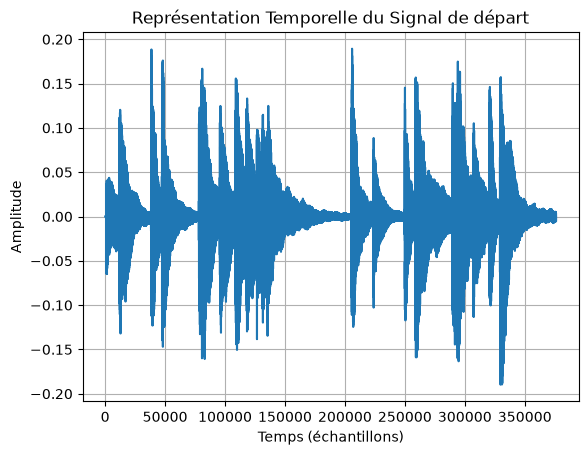

Le signal synthétisé a été enregistré sous le nom 'synthesized_audio.wav'


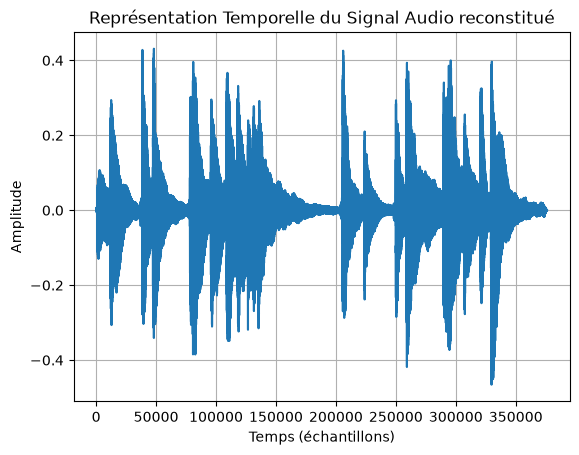

In [ ]:
# Main Film2
filename1 = 'C:/Users/Etudiant/OneDrive/Documents/fidel/Projet/programmation_Python/SourcesTP_OutilMath/Enregistrements/Film2.mp3'
# Paramètres de la fenêtre glissante
window_duration = 0.1
hop_duration = 0.02
valseuil = 0.05
main(filename1,window_duration,hop_duration,valseuil)

In [48]:
"""
Etude de l'enregistrement Constellation de Jade Lemac la version au violon
"""
from IPython.display import Audio, display
filename2 = r"C:\Users\Etudiant\OneDrive\Documents\fidel\Projet\programmation_Python\SourcesTP_OutilMath\Enregistrements\constellations_violin.mp3.mpeg"

signal, sr = librosa.load(filename2)
print("Fichier audio original constellation :")
display(Audio(signal, rate=sr))

Fichier audio original constellation :


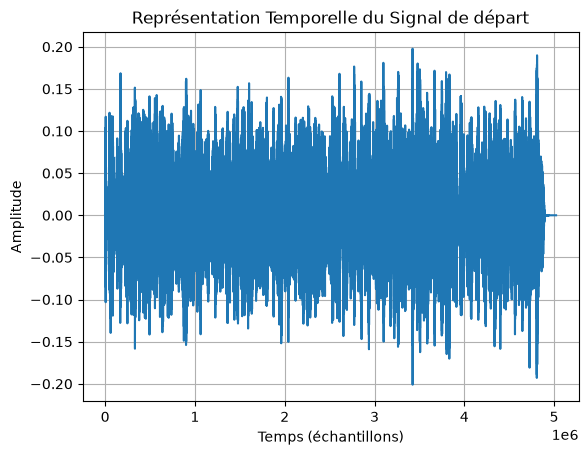

In [ ]:

#definition des paramètres de la fenêtre glissante pour l'étude de l'enregistrement Constellation de Jade Lemac la version au violon
window_duration = 0.1
hop_duration = 0.02
valseuil = 0.03

#main
main(filename2,window_duration,hop_duration,valseuil)

In [46]:
#FILM11


filename3 = "C:/Users/Etudiant/OneDrive/Documents/fidel/Projet/programmation_Python/SourcesTP_OutilMath/Enregistrements/Film11.mp3"

signal, sr = librosa.load(filename3)
print("Fichier audio original Film11 :")
IPython.display.Audio(filename3)

Fichier audio original Film11 :


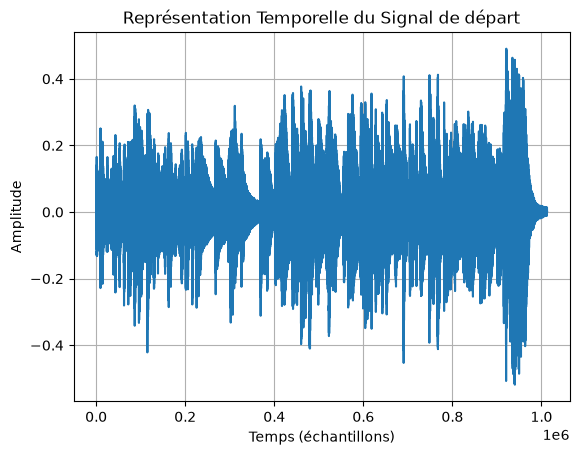

Le signal synthétisé a été enregistré sous le nom 'synthesized_audio.wav'


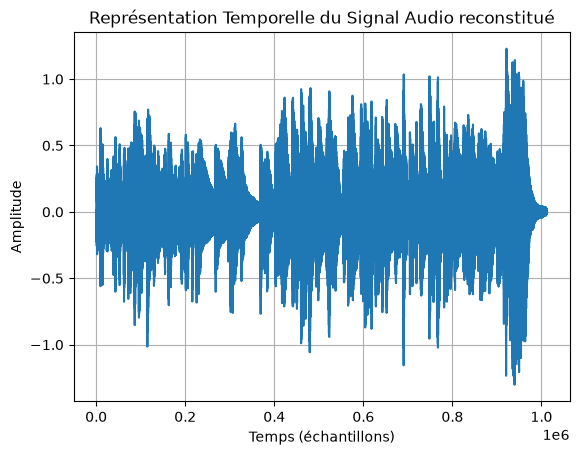

In [47]:
#definition des paramètres de la fenêtre glissante pour l'étude de l'enregistrement Constellation de Jade Lemac la version au violon
window_duration = 0.1
hop_duration = 0.02
valseuil = 0.03


#main
main(filename3,window_duration,hop_duration,valseuil)

In [44]:
#FILM6


filename4 = "C:/Users/Etudiant/OneDrive/Documents/fidel/Projet/programmation_Python/SourcesTP_OutilMath/Enregistrements/Film6.mp3"

signal, sr = librosa.load(filename4)
print("Fichier audio original Film6 :")
IPython.display.Audio(filename4)

Fichier audio original Film6 :


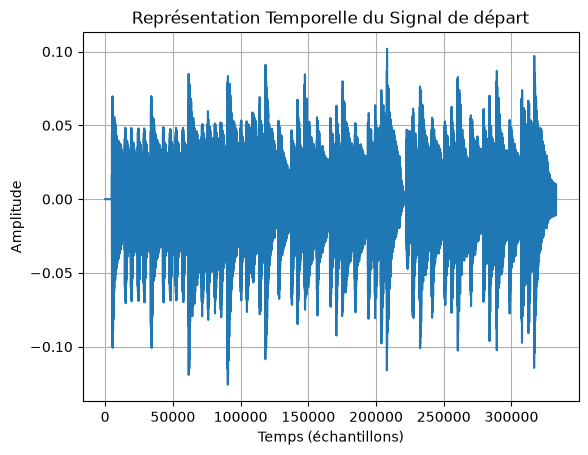

Le signal synthétisé a été enregistré sous le nom 'synthesized_audio.wav'


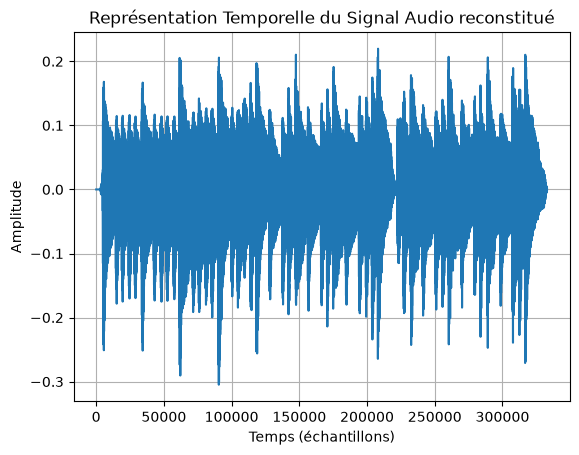

In [45]:
#definition des paramètres de la fenêtre glissante pour l'étude de l'enregistrement Constellation de Jade Lemac la version au violon
window_duration = 0.1
hop_duration = 0.02
valseuil = 0.03


#main
main(filename4,window_duration,hop_duration,valseuil)

# Vos Commentaires sur l'étude

Commenter votre étude pour chaque enregistrement et les résultats obtenus. 



## Enregistrement: Film2.mp3
**Nature du son.** Film2.mp3 est un extrait de 17s. On y trouve aussi bien des notes graves, que des notes médium. Les notes changent vite.

J'ai fais plusieurs tests mais les plus marquantes ou devrais je dire déterminante sont :

- le premier test : **Réglage A (départ)** : `window_duration = 0.5`, `hop_duration = 0.5`, `valseuil = 0.5`
- le test retenu : **Réglage B (retenu)** : `window_duration = 0.1`, `hop_duration = 0.025`, `valseuil = 0.05`

Lorsque j'ai fais le premier test, j'ai remarqué que non seulement de nombreuse notes étaient perdues mais il y avait également énormément de bruit. Aucun des trois paramètres n'était l'idéal. La première des choses que j'ai d'abord fais a été de récupérer les bonnes notes de l'orchestre pour cela il fallait agir sur deux paramètres à savoir `hop_duration` et `window_duration`. Mes remarques sonbt donc les suivantes : 

## Effet de `window_duration`
- **0,5 s** : La fenêtre mélange plusieurs accords successifs,  je n'arrivent plus donc à déceler les changements de notes et le son est cacophonique
- **0,1 s** : la fenêtre est assez courte donc j'arrive à récupérer les bonnes notes et changements de notes. Le son est donc plus ou moins complet.
- **0,05 s** : je ne distingue plus trop bien les notes graves donc j'ai décidé de rester sur **0.1**

## Effet de `hop_duration`
Avec `hop_duration = window_duration = 0.5 `, les fenêtres se touchent, ce qui crée un petit saut. Et j'ai remarqué que plus je diminuait hop duration en faisant glisser la fenêtre par pas plus petit mieux c'est. la valeur idéale sur laquelle j'ai fini par statuer etait donc : **0.02**

Ayant trouvé les valeurs de `window_duration` et de `hop_duration` pour lesquelles les notes de la partitions ressortent, il ne me restait que valseuil, car l'un est de retrouvé les bonnes notes mais l'autre est de faire ressortir la bonne harmonie avec le moins de bruit et le plus de précision possible.

## Effet du seuil `valseuil`
- **Seuil élevé (0,5)** : Il ne restait que les notes les plus fortes, et la reconstitution s'éloignait de l'original.
- **Seuil plus bas (0,05)** : Il y a moins de bruit et la reconstitution est plus ou moins plus fidèle. 
- **Seuil trop bas (0,0001)** : Le signal est presque recopié, presque toutes les fréquences sont prises, ce n'étaient plus les fréquence dominantes, je passais donc à côté  de l'analyse.  j'ai remarqué que le seuil est aussi bien  entre 0.01 et 0.1  mais j'ai décidé de rester sur 0.05 car il me semble le plus fidèle en terme de reconstitution.

## Conclusion
Pour Film2, le réglage retenu (**fenêtre 0,1 s, pas 0,02 s, seuil 0,05**) donne une reconstitution bien plus fidèle que le réglage de départ


## Enregistrement: constellations_violin.mp3
**Nature du son.** constellations_violin.mp3 est une partition jouée au violon d'une durée de 3 min 48s. Contrairement à Film2, il ne s'agit pas d'un orchestre mais d'un seul instrument et de manière général une seule note à la fois mais les notes s'enchainent assez vite quand même.

Parmis mes nombreux tests, les plus marquants sont les suivants:

- **Réglage** : `window_duration = 1`, `hop_duration = 1`, `valseuil = 0.5`
- le test retenu : **Réglage B** : `window_duration = 0.1`, `hop_duration = 0.02`, `valseuil = 0.03`

Avec le premier réglage, la mélodie était méconnaissable, je n'entendais qu'une partie des notes et la reconstitution etait emplie de bruits.Aucun des trois paramètres n'était bon au départ. J'ai donc chercher pas à pas. Mes remarques sont les suivantes: 


## Effet de `window_duration`
- **1 s** : Plusieurs notes essentielles étaient perdues, la mélodie était sans dessus dessous.
- **0,1 s** : étant assez courte, la fenêtre capte les bonnes note, les changement sont plus nettes.
- **0,05 s** : Les notes graves ne se distinguent plus.

## Effet de `hop_duration`
Pour une fenêtre de **0,1** la valeur pour laquelle les fenêtre n'avait pas de saut au niveau des jonction est celle de 0.02. Pour toute valeur supérieur ou égale à 0.1, la reconstitution s'éloigne de la mélodie de départ.

## Effet du seuil `valseuil`
- **Seuil élevé (0,5)** : Il ne restait que la note forte et les harmoniques disparaissaient, on s'éloignaient à nouveau de l'original. 
- **Seuil bas (0,03)** : Le timbre du violon est maintenu, le bruit est nettement dissipé.

## Conclusion
Pour constellations_violin.mp3, le réglage retenu (**fenêtre 0,1 s, pas 0,02 s, seuil 0,03**) donne une reconstitution assez fidèle. sur le violon, la fenêtre courte sert à suivre des notes qui s'enchaînent vite, et le seuil bas à conserver le timbre de l'instrument.

# Pour aller plus loin : principes de l'empreinte sonore et de l'application Shazam 



Vous avez recherché, pour chaque mesure, les $n$ fréquences correspondant aux $n$ plus grandes valeurs du module du spectre. Avec un nombre $n$ suffisant, vous avez constaté qu’il était possible de restituer un signal sonore quasiment identique à l’original. 

Le **spectrogramme** est ainsi une représentation caractéristique d’un enregistrement musical. Mais il contient beaucoup d’informations redondantes. Il est alors possible d’extraire à partir de cette représentation des « signatures » ou « empreintes » des morceaux de musique un peu à l’image des empreintes digitales pour l’identification de personnes. Les systèmes de reconnaissance musicale permettent ainsi de comparer la signature d’un morceau de musique inconnu à l’ensemble des signatures préalablement calculées et stockées dans une base de données.


Mais il est possible de détecter encore moins de fréquences par mesure, si le but n’est pas de restituer le son original, mais de produire une « marque », appelée **empreinte sonore**, qui puisse caractériser un morceau de musique de manière unique comme le montre la figure suivante.


<img src="./EmpreinteSonore.png" width="1000" height="800">



L’**application Shazam** détecte $n = 6$ fréquences seulement par mesure. Mais au lieu de chercher ces fréquences dans la bande $[f_{min}, f_{max}]$, elle découpe cette bande en $n = 6$ sous-bandes, et cherche dans chaque sous-bande la fréquence correspondant à la plus grande valeur du module du spectre.

La création d’**une base d’empreintes sonores** consiste à numériser un certain nombre de morceaux de musique (la base de l’application Shazam est gigantesque) servant par la suite à une méthode d'apprentissage automatique pour réaliser le reconnaissance du morceau musical. 
